In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

splits = {
    'train': 'emotion/train-00000-of-00001.parquet', 
    'val': 'emotion/validation-00000-of-00001.parquet',
    'test': 'emotion/test-00000-of-00001.parquet', 
}
df_train = pd.read_parquet("hf://datasets/cardiffnlp/tweet_eval/" + splits["train"])
df_val = pd.read_parquet("hf://datasets/cardiffnlp/tweet_eval/" + splits["val"])
df_test = pd.read_parquet("hf://datasets/cardiffnlp/tweet_eval/" + splits["test"])

In [36]:
df_train["split"], df_val["split"], df_test["split"] = "train", "val", "test"
df = pd.concat([df_train, df_val, df_test])

In [ ]:
df.shape

(5052, 2)

In [21]:
df.isna().sum()

text     0
label    0
dtype: int64

In [22]:
print('Train:', df_train.duplicated().sum())
print('Test', df_test.duplicated().sum())
print('Validation', df_val.duplicated().sum())

Train: 25
Test 0
Validation 0


In [24]:
df_train = df_train.drop_duplicates()
df = df.drop_duplicates()

In [25]:
df.duplicated().sum()

np.int64(0)

In [23]:
train_set, val_set, test_set = set(df_train.text), set(df_val.text), set(df_test.text)
print("train ∩ val :", len(train_set & val_set))
print("train ∩ test:", len(train_set & test_set))
print("val ∩ test  :", len(val_set & test_set))

train ∩ val : 0
train ∩ test: 0
val ∩ test  : 0


In [26]:
import os

output_path = "../data/raw"
os.makedirs(output_path, exist_ok=True)

df_train.to_csv(rf"{output_path}/train.csv", index=False)
df_val.to_csv(rf"{output_path}/val.csv", index=False)
df_test.to_csv(rf"{output_path}/test.csv", index=False)

In [38]:
label_names = {0: "anger", 1: "joy", 2: "optimism", 3: "sadness"}
df['emotion'] = df['label'].map(label_names)

In [39]:
overview = df.groupby("split").size().reindex(["train", "val", "test"]).to_frame("rows")
overview["classes"] = df.groupby("split")["emotion"].nunique()
overview

,rows,classes
split,,
train,3232,4
val,374,4
test,1421,4


emotion,anger,joy,optimism,sadness
split,,,,
test,39.3,25.2,8.7,26.9
train,43.3,21.1,9.1,26.5
val,42.8,25.9,7.5,23.8


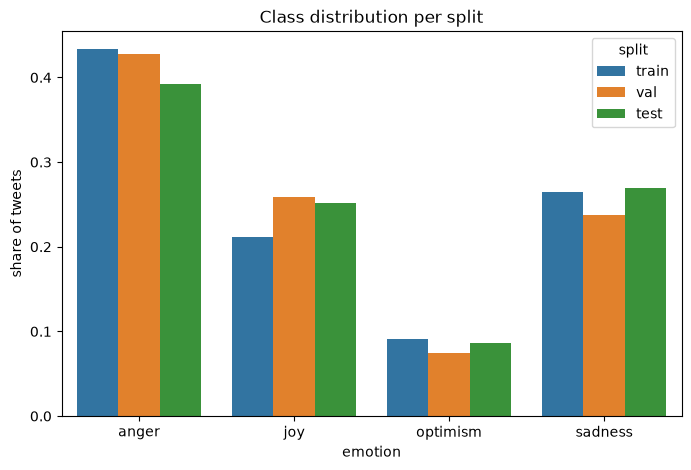

In [40]:
order = ["anger", "joy", "optimism", "sadness"]
dist = (df.groupby("split")["emotion"].value_counts(normalize=True)
          .rename("share").reset_index())
display((dist.pivot(index="split", columns="emotion", values="share")[order] * 100).round(1))

plt.figure(figsize=(8, 5))
sns.barplot(data=dist, x="emotion", y="share", hue="split", order=order, hue_order=["train", "val", "test"])
plt.title("Class distribution per split")
plt.ylabel("share of tweets")
plt.show()

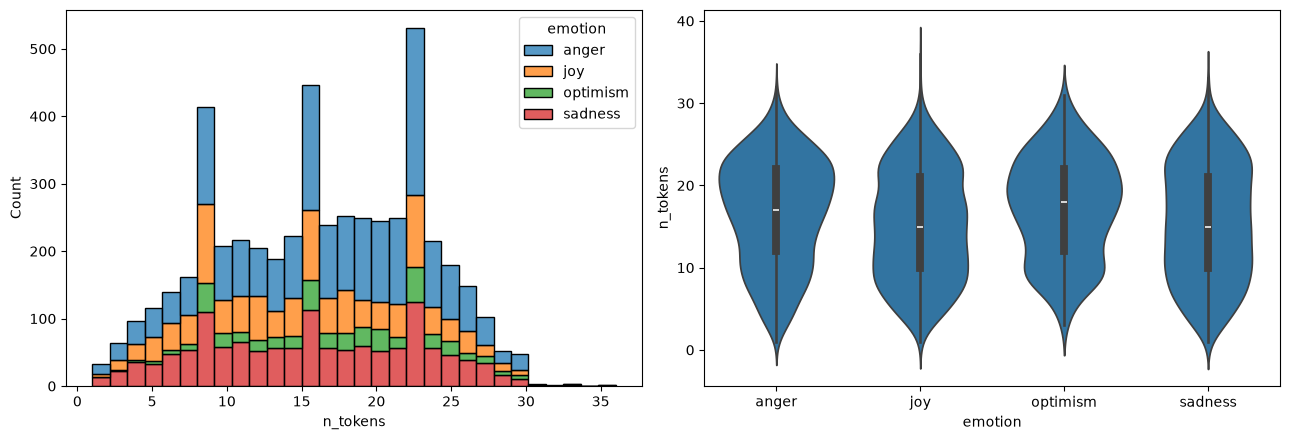

In [42]:
df["n_chars"] = df["text"].str.len()
df["n_tokens"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="n_tokens", hue="emotion", hue_order=order, multiple="stack", bins=30, ax=axes[0])
sns.violinplot(data=df, x="emotion", y="n_tokens", order=order, ax=axes[1])
plt.tight_layout(); plt.show()

In [43]:
df.groupby("emotion")[["n_tokens", "n_chars"]].describe().round(1)

n_tokens                                         n_chars              \
            count  mean  std  min   25%   50%   75%   max   count  mean   std   
emotion                                                                         
anger      2118.0  16.7  6.5  1.0  12.0  17.0  22.0  32.0  2118.0  94.6  36.0   
joy        1138.0  15.2  6.6  1.0  10.0  15.0  21.0  36.0  1138.0  86.1  36.4   
optimism    445.0  17.2  6.2  3.0  12.0  18.0  22.0  31.0   445.0  99.0  33.2   
sadness    1326.0  15.5  7.0  1.0  10.0  15.0  21.0  33.0  1326.0  86.1  38.3   

                                           
           min   25%    50%    75%    max  
emotion                                    
anger      6.0  66.0  102.0  127.0  152.0  
joy       10.0  55.0   87.0  120.8  148.0  
optimism  18.0  74.0  105.0  128.0  160.0  
sadness    6.0  54.0   88.0  122.0  158.0

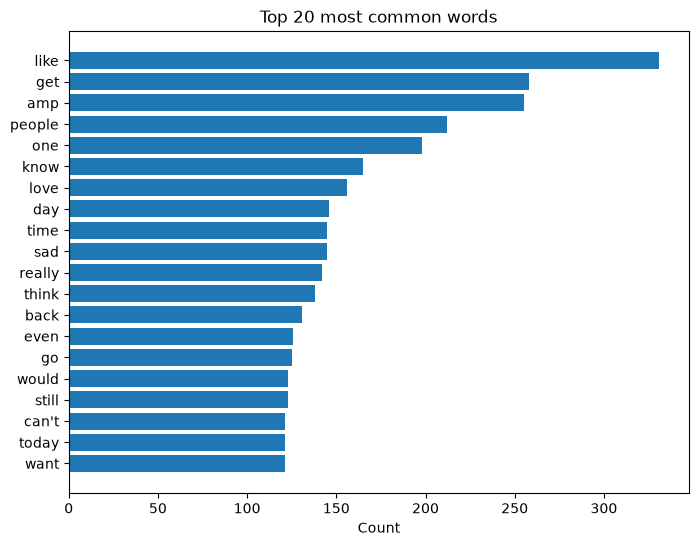

In [31]:
import re
from collections import Counter
import matplotlib.pyplot as plt
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

def get_words(text):
    text = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", text.lower())
    words = re.findall(r"[a-z']+", text)
    return [w for w in words if w not in stop_words and len(w) > 1]

all_words = Counter(w for t in df["text"] for w in get_words(t))
common = all_words.most_common(20)

words, counts = zip(*common)
plt.figure(figsize=(8, 6))
plt.barh(words[::-1], counts[::-1])
plt.title("Top 20 most common words")
plt.xlabel("Count")
plt.show()

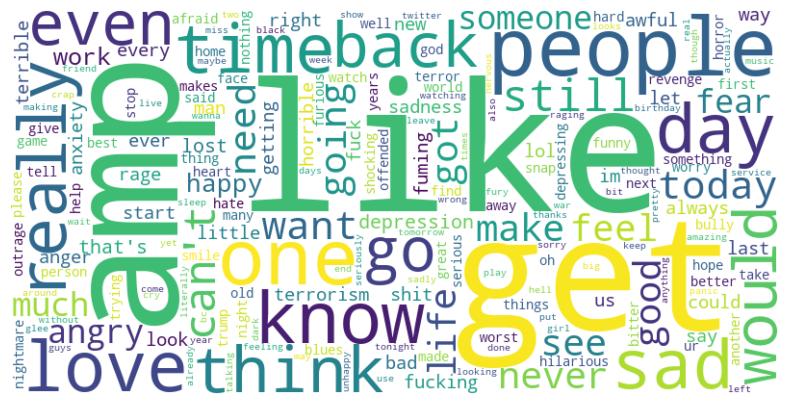

In [32]:
from wordcloud import WordCloud

wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(all_words)
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

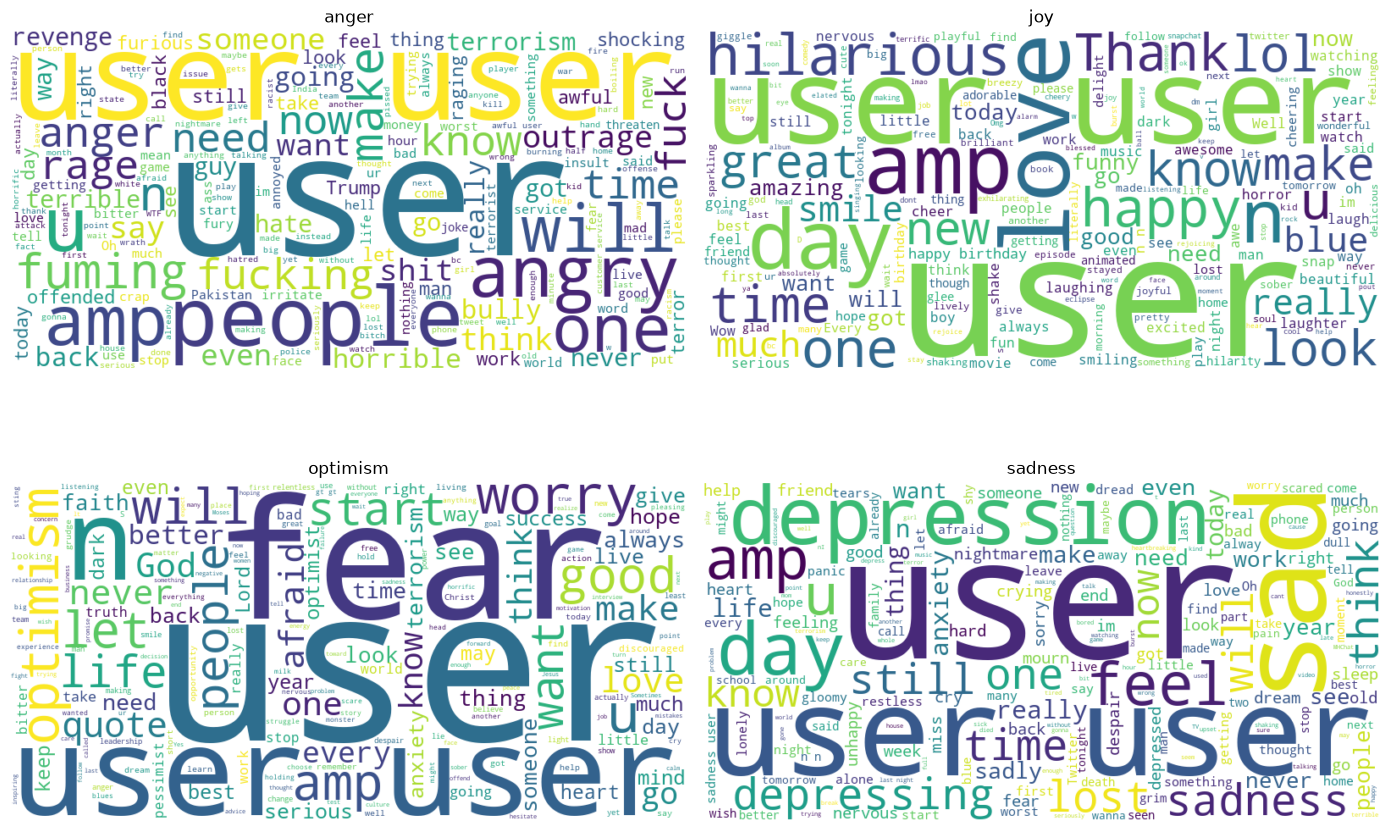

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, emotion in zip(axes.flat, label_names.values()):
    text = " ".join(df.loc[df["emotion"] == emotion, "text"])
    cloud = WordCloud(width=800, height=400, background_color="white").generate(text)
    axis.imshow(cloud, interpolation="bilinear")
    axis.set_title(emotion)
    axis.axis("off")
plt.tight_layout()
plt.show()

In [44]:
patterns = {
    "mention":    r"@\w+",
    "hashtag":    r"#\w+",
    "url":        r"https?://\S+|www\.\S+",
    "emoji":      r"[\U0001F300-\U0001FAFF\u2600-\u27BF]",
    "elongated":  r"(\w)\1{2,}",
    "ALL-CAPS":   r"\b[A-Z]{3,}\b",
    "contraction": r"\b\w+'\w+\b",
}
noise = pd.DataFrame({k: df["text"].str.contains(p, regex=True) for k, p in patterns.items()})
noise["emotion"] = df["emotion"]
print((noise.groupby("emotion").mean().T * 100).round(1))
print("\nAll tweets:", (noise.drop(columns="emotion").mean() * 100).round(1).to_dict())

emotion      anger   joy  optimism  sadness
mention       50.0  48.6      30.6     35.1
hashtag       43.1  44.7      47.0     47.7
url            0.0   0.0       0.0      0.0
emoji         11.2  27.2       5.2     17.8
elongated      2.1   2.7       0.0      2.0
ALL-CAPS      11.9  11.2       7.9      6.4
contraction   34.4  28.2      37.8     34.8

All tweets: {'mention': 44.1, 'hashtag': 45.0, 'url': 0.0, 'emoji': 16.0, 'elongated': 2.0, 'ALL-CAPS': 9.9, 'contraction': 33.4}


/var/folders/v3/bhw57lh559n7y8rdbsscq2bc0000gn/T/ipykernel_56402/3494016550.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  noise = pd.DataFrame({k: df["text"].str.contains(p, regex=True) for k, p in patterns.items()})


In [45]:
import emoji
from collections import Counter

for e in order:
    sub = df.loc[df["emotion"] == e, "text"]
    tags = Counter(t.lower() for s in sub for t in re.findall(r"#\w+", s))
    emos = Counter(x["emoji"] for s in sub for x in emoji.emoji_list(s))
    print(f"{e:9s} hashtags: {tags.most_common(8)}")
    print(f"{'':9s} emoji   : {emos.most_common(8)}\n")

anger     hashtags: [('#angry', 44), ('#fuming', 40), ('#awful', 39), ('#rage', 36), ('#terrible', 29), ('#horrible', 29), ('#shocking', 29), ('#anger', 28)]
          emoji   : [('😂', 54), ('😡', 50), ('😠', 27), ('😤', 22), ('🙄', 16), ('🙈', 12), ('🔥', 11), ('🙃', 11)]

joy       hashtags: [('#hilarious', 32), ('#blues', 23), ('#happy', 17), ('#funny', 14), ('#smile', 12), ('#horror', 12), ('#lol', 11), ('#amazing', 11)]
          emoji   : [('😂', 103), ('😍', 32), ('❤️', 19), ('😘', 18), ('😊', 18), ('💖', 16), ('😭', 15), ('🤣', 14)]

optimism  hashtags: [('#fear', 19), ('#optimism', 18), ('#quote', 14), ('#worry', 10), ('#terrorism', 9), ('#afraid', 9), ('#faith', 9), ('#life', 7)]
          emoji   : [('✨', 74), ('🙈', 2), ('🍃', 2), ('🙏🏾', 2), ('😂', 2), ('❤', 2), ('✌', 1), ('👌', 1)]

sadness   hashtags: [('#sad', 71), ('#depression', 55), ('#sadness', 51), ('#anxiety', 33), ('#depressing', 26), ('#lost', 25), ('#nightmare', 22), ('#depressed', 14)]
          emoji   : [('😭', 47), ('😢', 31), 

In [46]:
import numpy as np
class_counts = {e: Counter(w for t in df.loc[df["emotion"] == e, "text"] for w in get_words(t)) for e in order}
vocab_total = sum((c for c in class_counts.values()), Counter())

def distinctive(e, top=12, min_count=15, alpha=1):
    other = vocab_total - class_counts[e]
    n_e, n_o = sum(class_counts[e].values()), sum(other.values())
    rows = []
    for w, c in class_counts[e].items():
        if vocab_total[w] >= min_count:
            lo = np.log((c + alpha) / (n_e + alpha)) - np.log((other[w] + alpha) / (n_o + alpha))
            rows.append((w, round(lo, 2), c))
    return sorted(rows, key=lambda r: -r[1])[:top]

for e in order:
    print(e, distinctive(e), "\n")

anger [('fuming', np.float64(4.57), 73), ('outrage', np.float64(4.41), 62), ('irritate', np.float64(3.6), 27), ('threaten', np.float64(3.36), 21), ('angry', np.float64(3.22), 95), ('raging', np.float64(3.18), 36), ('rage', np.float64(3.13), 69), ('bitch', np.float64(3.1), 16), ('pissed', np.float64(3.1), 16), ('revenge', np.float64(3.08), 49), ('fuck', np.float64(3.05), 64), ('insult', np.float64(3.01), 30)] 

joy [('birthday', np.float64(4.3), 41), ('hilarious', np.float64(3.86), 53), ('awesome', np.float64(3.5), 18), ('sparkling', np.float64(3.27), 14), ('amazing', np.float64(3.17), 33), ('smiling', np.float64(3.05), 17), ('laughter', np.float64(2.91), 20), ('delight', np.float64(2.86), 14), ('beautiful', np.float64(2.86), 19), ('cheering', np.float64(2.86), 14), ('hilarity', np.float64(2.79), 13), ('excited', np.float64(2.78), 22)] 

optimism [('optimism', np.float64(5.01), 30), ('worry', np.float64(2.79), 31), ('quote', np.float64(2.65), 15), ('fear', np.float64(2.17), 47), ('pessi

vocabulary: 11347 | appear once: 59.0%


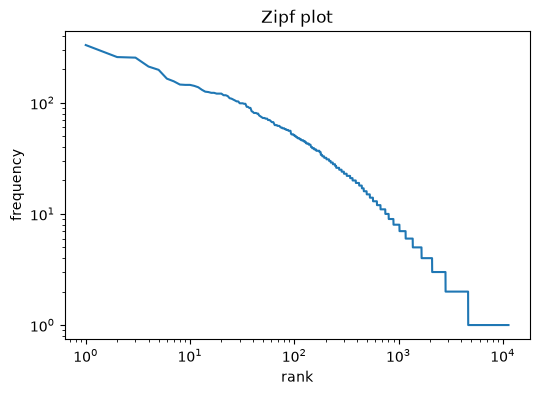

In [47]:
freq = Counter(w for t in df["text"] for w in get_words(t))
counts = np.array(sorted(freq.values(), reverse=True))
print("vocabulary:", len(freq), "| appear once:", f"{(counts == 1).mean():.1%}")

plt.figure(figsize=(6, 4))
plt.loglog(np.arange(1, len(counts) + 1), counts)
plt.xlabel("rank"); plt.ylabel("frequency"); plt.title("Zipf plot")
plt.show()

In [48]:
for e in order:
    print(f"--- {e}")
    for t in df.loc[df["emotion"] == e, "text"].sample(4, random_state=42):
        print("  •", t)

--- anger
  • @user The hatred from the Left ought to concern everyone----who wants a police state-the left, so than can spy on all of us.
  • @user : Whaaaat?!? Oh hell no. I was jealous because you got paid to fuck, but this is a whole new level. #anger #love #conflicted😬
  • @user now im feeling the
  • A black female LEO💙 was shot 8 times and died in Philadelphia --Where's the #outrage black people? @user #Sharpton #blm #TheFive
--- joy
  • IK to PMLN: 'Darling, I will haunt you in your nightmares, dressed like a dream.' BEST THING EVER. #GameOverNawaz
  • No legit though this is my first ever experience and it's when I don't wear makeup so was pretty ironic tbh #giggle but no ta pal
  • Val reminds me of one of the cheerful witches that looks after Aurora in Disney’s Sleeping Beauty. #GBBO
  • The lecturer tonight had such a muppet frown it was great.
--- optimism
  • just looked at wood's goal again and i dont think his first chance is that bad a miss, horrible height hit hard an